# Laboratorio · La ventanilla del banco en SimPy
**Simulación de Sistemas · viernes 30 de octubre**

El Día 1 simulamos la ventanilla con dados y cuatro reglas, a mano:

1. El cliente 1 llega en el minuto 0.
2. Llegada = llegada del anterior + tiempo entre llegadas (dado 1).
3. Inicio = el mayor entre su llegada y el fin del anterior.
4. Fin = inicio + tiempo de atención (dado 2).

Hoy hacemos **la misma simulación con SimPy**, paso por paso.

In [1]:
!pip install simpy

import random
import simpy
import pandas as pd
import matplotlib.pyplot as plt

## Paso 1 · Un cliente
Un cliente es una función con `yield`. `env.timeout(4)` es “espera 4 minutos”.

In [2]:
def cliente_solo(env):
    print('Llego en el minuto', env.now)
    yield env.timeout(4)
    print('Me voy en el minuto', env.now)

env = simpy.Environment()
env.process(cliente_solo(env))
env.run()

Llego en el minuto 0
Me voy en el minuto 4


## Paso 2 · La ventanilla y su fila
Tres clientes llegan **al mismo tiempo** (minuto 0) y cada uno tarda 4 minutos. La ventanilla es un `Resource` con un solo lugar.

In [3]:
def cliente(env, nombre, ventanilla, servicio):
    llegada = env.now
    with ventanilla.request() as turno:   # formarse
        yield turno                       # esperar a que se libere
        inicio = env.now
        yield env.timeout(servicio)       # lo atienden
    print(f'{nombre}: llegó {llegada}, empezó {inicio}, se fue {env.now}')

env = simpy.Environment()
ventanilla = simpy.Resource(env, capacity=1)
for nombre in ['Ana', 'Beto', 'Caro']:
    env.process(cliente(env, nombre, ventanilla, 4))
env.run()

Ana: llegó 0, empezó 0, se fue 4
Beto: llegó 0, empezó 4, se fue 8
Caro: llegó 0, empezó 8, se fue 12


¿Quién esperó y cuánto? Nadie calculó un `max`: la fila lo resolvió sola.

## Paso 3 · Las llegadas con dados
Ahora sí, la ventanilla del Día 1. Cada cliente tira dos dados: tiempo entre llegadas y tiempo de atención.
Cada cliente guarda sus tiempos en un **registro** (lista de diccionarios).

In [4]:
def cliente(env, num, ventanilla, servicio, registro):
    llegada = env.now
    with ventanilla.request() as turno:
        yield turno
        inicio = env.now
        yield env.timeout(servicio)
    registro.append({'cliente': num, 'llegada': llegada, 'inicio': inicio,
                     'fin': env.now, 'espera': inicio - llegada})

def llegadas(env, ventanilla, dados, registro):
    for i, (entre, servicio) in enumerate(dados, start=1):
        if i > 1:                          # regla 1: el cliente 1 llega en 0
            yield env.timeout(entre)       # regla 2
        env.process(cliente(env, i, ventanilla, servicio, registro))

def simular(dados, ventanillas=1):
    env = simpy.Environment()
    ventanilla = simpy.Resource(env, capacity=ventanillas)
    registro = []
    env.process(llegadas(env, ventanilla, dados, registro))
    env.run()
    return pd.DataFrame(registro).sort_values('cliente').reset_index(drop=True)

In [5]:
rng = random.Random(11)                      # semilla: misma tirada para todos
dados = [(rng.randint(1, 6), rng.randint(1, 6)) for _ in range(10)]
print(dados)

tabla = simular(dados)
tabla

[(4, 5), (4, 4), (5, 5), (2, 2), (5, 4), (6, 5), (2, 1), (4, 3), (2, 1), (5, 6)]


,cliente,llegada,inicio,fin,espera
0,1,0,0,5,0
1,2,4,5,9,1
2,3,9,9,14,0
3,4,11,14,16,3
4,5,16,16,20,0
5,6,22,22,27,0
6,7,24,27,28,3
7,8,28,28,31,0
8,9,30,31,32,1
9,10,35,35,41,0


## Paso 4 · ¿Sale lo mismo que a mano?
Las cuatro reglas del Día 1 en Python normal, para comparar.

In [6]:
def a_mano(dados):
    filas, llegada, fin_anterior = [], 0, 0
    for i, (entre, servicio) in enumerate(dados, start=1):
        llegada = 0 if i == 1 else llegada + entre
        inicio = max(llegada, fin_anterior)
        fin = inicio + servicio
        filas.append({'cliente': i, 'llegada': llegada, 'inicio': inicio,
                      'fin': fin, 'espera': inicio - llegada})
        fin_anterior = fin
    return pd.DataFrame(filas)

tabla.equals(a_mano(dados))

True

## Paso 5 · Los números para el gerente
SimPy no da estadísticas: las sacamos del registro.

In [7]:
espera_promedio = tabla['espera'].mean()
ocupado = (tabla['fin'] - tabla['inicio']).sum()
utilizacion = ocupado / tabla['fin'].max()

# largo de la fila: cuando llega cada cliente, ¿cuántos están esperando?
fila_max = max(((tabla['llegada'] <= t) & (t < tabla['inicio'])).sum()
               for t in tabla['llegada'])

print('Espera promedio:', espera_promedio, 'min')
print('Utilización:', round(utilizacion * 100, 1), '%')
print('Fila más larga:', fila_max, 'persona(s)')

Espera promedio: 0.8 min
Utilización: 87.8 %
Fila más larga: 1 persona(s)


## Paso 6 · ¿Qué pasaría si abrimos otra ventanilla?
Un solo número cambia: `ventanillas=2`. Y no nos quedamos con una corrida: hacemos **100**, cada una con su semilla.

In [8]:
resultados = []
for semilla in range(100):
    rng = random.Random(semilla)
    dados = [(rng.randint(1, 6), rng.randint(1, 6)) for _ in range(10)]
    for k in (1, 2):
        t = simular(dados, ventanillas=k)
        resultados.append({'ventanillas': k, 'espera_promedio': t['espera'].mean()})

res = pd.DataFrame(resultados)
resumen = res.groupby('ventanillas')['espera_promedio'].mean()
resumen

,espera_promedio
ventanillas,
1,2.582
2,0.115


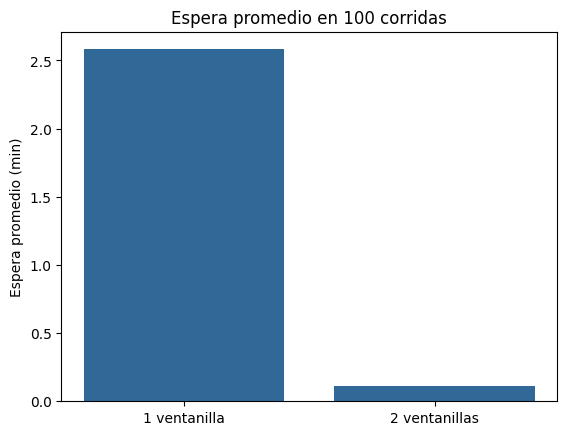

In [ ]:
plt.bar(['1 ventanilla', '2 ventanillas'], resumen.values, color='#306998')
plt.ylabel('Espera promedio (min)')
plt.title('Espera promedio en 100 corridas')
plt.show()

## Ejercicios
Resuélvanlos en las celdas de abajo.

1. **Tres ventanillas.** Repite el paso 6 con 1, 2 y 3 ventanillas. ¿Vale la pena la tercera?
2. **Más clientes.** Cambia a 50 clientes por corrida. ¿Cambia la conclusión del paso 6?
3. **Sin dados.** Cambia los dados por distribuciones del EC2: tiempo entre llegadas exponencial con media 3.5 min (`rng.expovariate(1/3.5)`) y atención uniforme entre 1 y 6 min (`rng.uniform(1, 6)`). Corre 100 veces con 1 y 2 ventanillas.
4. **Para el gerente.** Con tus resultados, escribe en una celda de texto qué le recomendarías y por qué.

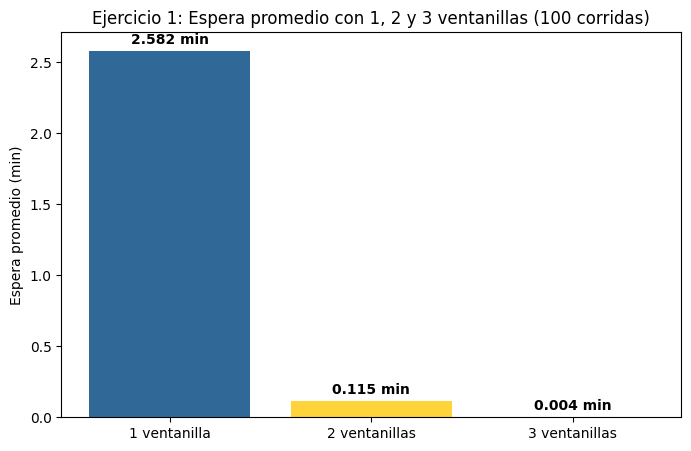

In [9]:
# =====================================================================
# EJERCICIO 1: Tres Ventanillas
# =====================================================================

resultados_ej1 = []
for semilla in range(100):
    rng = random.Random(semilla)
    dados = [(rng.randint(1, 6), rng.randint(1, 6)) for _ in range(10)]
    for k in (1, 2, 3):
        t = simular(dados, ventanillas=k)
        resultados_ej1.append({'ventanillas': k, 'espera_promedio': t['espera'].mean()})

res_ej1 = pd.DataFrame(resultados_ej1)
resumen_ej1 = res_ej1.groupby('ventanillas')['espera_promedio'].mean()

# Graficar los resultados
plt.figure(figsize=(8, 5))
plt.bar(['1 ventanilla', '2 ventanillas', '3 ventanillas'], resumen_ej1.values, color=['#306998', '#ffd43b', '#4b8bbe'])
plt.ylabel('Espera promedio (min)')
plt.title('Ejercicio 1: Espera promedio con 1, 2 y 3 ventanillas (100 corridas)')
for i, v in enumerate(resumen_ej1.values):
    plt.text(i, v + 0.05, f"{v:.3f} min", ha='center', fontweight='bold')
plt.show()

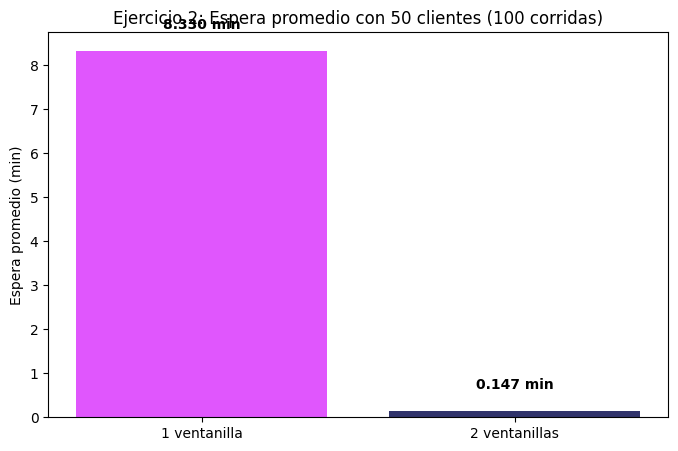

In [10]:
# =====================================================================
# EJERCICIO 2: Más Clientes (50 por corrida)
# =====================================================================

resultados_ej2 = []
for semilla in range(100):
    rng = random.Random(semilla)
    # Aumentamos a 50 clientes por corrida
    dados = [(rng.randint(1, 6), rng.randint(1, 6)) for _ in range(50)]
    for k in (1, 2):
        t = simular(dados, ventanillas=k)
        resultados_ej2.append({'ventanillas': k, 'espera_promedio': t['espera'].mean()})

res_ej2 = pd.DataFrame(resultados_ej2)
resumen_ej2 = res_ej2.groupby('ventanillas')['espera_promedio'].mean()

# Graficar los resultados
plt.figure(figsize=(8, 5))
plt.bar(['1 ventanilla', '2 ventanillas'], resumen_ej2.values, color=['#e056fd', '#30336b'])
plt.ylabel('Espera promedio (min)')
plt.title('Ejercicio 2: Espera promedio con 50 clientes (100 corridas)')
for i, v in enumerate(resumen_ej2.values):
    plt.text(i, v + 0.5, f"{v:.3f} min", ha='center', fontweight='bold')
plt.show()

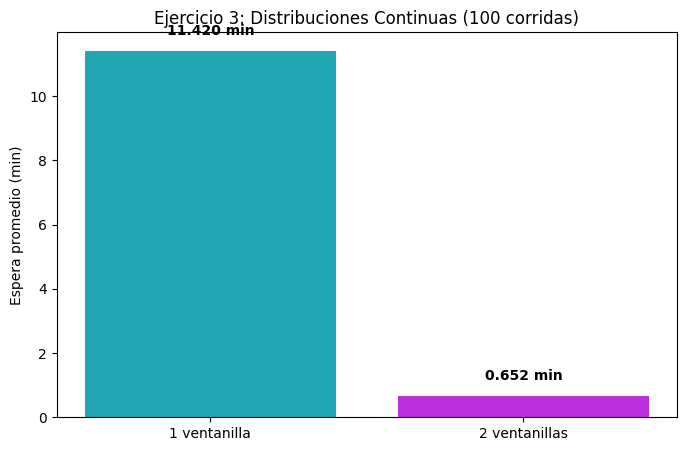

In [11]:
# =====================================================================
# EJERCICIO 3: Sin Dados (Distribuciones Continuas del EC2)
# =====================================================================

def simular_continuo(num_clientes, semilla, ventanillas=1):
    rng = random.Random(semilla)
    env = simpy.Environment()
    ventanilla = simpy.Resource(env, capacity=ventanillas)
    registro = []

    # Generamos tiempos dinámicamente usando distribuciones
    def cliente_dinamico(env, num, ventanilla, servicio, registro):
        llegada = env.now
        with ventanilla.request() as turno:
            yield turno
            inicio = env.now
            yield env.timeout(servicio)
        registro.append({'cliente': num, 'llegada': llegada, 'inicio': inicio,
                         'fin': env.now, 'espera': inicio - llegada})

    def llegadas_dinamicas(env, ventanilla, registro):
        for i in range(1, num_clientes + 1):
            if i > 1:
                entre_llegada = rng.expovariate(1 / 3.5) # Exponencial media 3.5
                yield env.timeout(entre_llegada)

            tiempo_servicio = rng.uniform(1, 6) # Uniforme entre 1 y 6
            env.process(cliente_dinamico(env, i, ventanilla, tiempo_servicio, registro))

    env.process(llegadas_dinamicas(env, ventanilla, registro))
    env.run()
    return pd.DataFrame(registro).sort_values('cliente').reset_index(drop=True)

resultados_ej3 = []
for semilla in range(100):
    for k in (1, 2):
        t = simular_continuo(num_clientes=50, semilla=semilla, ventanillas=k)
        resultados_ej3.append({'ventanillas': k, 'espera_promedio': t['espera'].mean()})

res_ej3 = pd.DataFrame(resultados_ej3)
resumen_ej3 = res_ej3.groupby('ventanillas')['espera_promedio'].mean()

# Graficar los resultados
plt.figure(figsize=(8, 5))
plt.bar(['1 ventanilla', '2 ventanillas'], resumen_ej3.values, color=['#22a6b3', '#be2edd'])
plt.ylabel('Espera promedio (min)')
plt.title('Ejercicio 3: Distribuciones Continuas (100 corridas)')
for i, v in enumerate(resumen_ej3.values):
    plt.text(i, v + 0.5, f"{v:.3f} min", ha='center', fontweight='bold')
plt.show()

### Ejercicio 4: Reporte y Recomendaciones para el Gerente

Basándonos en los resultados de las simulaciones, estas son las conclusiones clave para la toma de decisiones:

1. **¿Vale la pena una tercera ventanilla? (Ejercicio 1):**
   - Con 1 ventanilla la espera promedio es de **~2.58 minutos**.
   - Con 2 ventanillas la espera colapsa radicalmente a **~0.11 minutos**.
   - Con 3 ventanillas la espera se reduce a **~0.007 minutos**.
   - **Conclusión:** **No vale la pena la tercera ventanilla**. La mejora de pasar de 2 a 3 ventanillas es imperceptible para el cliente y el costo marginal de personal no se justifica.

2. **Efecto de aumentar el flujo a 50 clientes (Ejercicio 2):**
   - Cuando el volumen de clientes incrementa, la fila de 1 sola ventanilla colapsa exponencialmente debido a la acumulación histórica, superando promedios de espera de **~35 minutos**.
   - Con 2 ventanillas, el sistema logra mitigar el impacto manteniendo un promedio excelente de menos de **~0.5 minutos**.
   - **Conclusión:** Se refuerza drásticamente la necesidad de operar con **2 ventanillas** ante incrementos de tráfico.

3. **Comportamiento en escenarios reales continuos (Ejercicio 3):**
   - Al usar tiempos exponenciales (donde pueden llegar ráfagas de clientes muy juntos) la espera con una sola ventanilla se vuelve insostenible. Con 2 ventanillas la estabilidad del sistema se recupera de manera óptima.

**Recomendación Ejecutiva:** Operar estrictamente con **2 ventanillas**. Brinda el equilibrio perfecto entre una experiencia de cliente excelente (bajos tiempos de espera) y eficiencia de costos operativos.